# Hypertension Classification with NHANES

An exploratory portfolio analysis of current hypertension status using
NHANES August 2021–August 2023. Saved results come from the author’s
local run. See README.md for setup, methods, results, and limitations.

Coefficient plots labeled “risk-increasing/decreasing” describe model
associations on the log-odds scale, not causal effects or future risk.


## A Note on Survey Weights

NHANES uses a complex survey design. This project does not apply
survey weights or account for survey strata and clusters.

All charts, prevalence percentages, model metrics, and subgroup
comparisons therefore describe the analyzed sample. They should
not be interpreted as nationally representative U.S. estimates.

The separate Statsmodels regression is exploratory. Its standard
errors, confidence intervals, and p-values do not account for the
complex survey design or uncertainty introduced by imputation.

Population-level inference would require an analysis incorporating
the appropriate survey weights and design variables.

In [51]:
# =============================================================================
# NHANES Cardiovascular Risk — Data Cleaning & Preparation
# =============================================================================
# Dataset: NHANES Cycle L (2021–2023)
# Goal: Build a clean, analysis-ready dataset to explore cardiovascular risk
#       factors across demographic groups in the U.S. population.
#
# Files used:
#   DEMO_L  — Demographics (age, sex, race, education, income)
#   TCHOL_L — Total cholesterol
#   BMX_L   — Body measurements (BMI, waist circumference)
#   BPXO_L  — Oscillometric blood pressure readings
#   BPQ_L   — Blood pressure questionnaire (diagnosis, medication)
#   SMQ_L   — Smoking history
#   MCQ_L   — Medical conditions (arthritis, heart failure, CHD, heart attack, stroke)
# =============================================================================

import pandas as pd
import numpy as np
from functools import reduce

# -----------------------------------------------------------------------------
# STEP 1: Load raw files
# -----------------------------------------------------------------------------

print("Loading raw NHANES files...")

demo  = pd.read_sas('/Users/heidisaldana/Downloads/DEMO_L.xpt', format='xport')
tchol = pd.read_sas('/Users/heidisaldana/Downloads/TCHOL_L.xpt', format='xport')
bmx = pd.read_sas('/Users/heidisaldana/Downloads/BMX_L.xpt.txt', format='xport')
bpxo  = pd.read_sas('/Users/heidisaldana/Downloads/BPXO_L.xpt', format='xport')
bpq   = pd.read_sas('/Users/heidisaldana/Downloads/BPQ_L.xpt', format='xport')
smq   = pd.read_sas('/Users/heidisaldana/Downloads/SMQ_L.xpt', format='xport')
mcq   = pd.read_sas('/Users/heidisaldana/Downloads/MCQ_L.xpt', format='xport')

print(f"  DEMO:  {demo.shape}")
print(f"  TCHOL: {tchol.shape}")
print(f"  BMX:   {bmx.shape}")
print(f"  BPXO:  {bpxo.shape}")
print(f"  BPQ:   {bpq.shape}")
print(f"  SMQ:   {smq.shape}")
print(f"  MCQ:   {mcq.shape}")

# -----------------------------------------------------------------------------
# STEP 2: Select relevant columns from each file
# -----------------------------------------------------------------------------
# We keep only variables with clinical or demographic meaning for
# cardiovascular risk. Variables with >85% missingness (e.g. SMD650 —
# cigarettes per day) are dropped as they are not usable for analysis.

demo_cols  = demo[['SEQN', 'RIAGENDR', 'RIDAGEYR', 'RIDRETH3',
                    'DMDEDUC2', 'INDFMPIR']]

tchol_cols = tchol[['SEQN', 'LBXTC']]

bmx_cols   = bmx[['SEQN', 'BMXBMI', 'BMXWAIST']]

bpxo_cols  = bpxo[['SEQN',
                    'BPXOSY1', 'BPXOSY2', 'BPXOSY3',   # systolic readings
                    'BPXODI1', 'BPXODI2', 'BPXODI3']]  # diastolic readings

bpq_cols   = bpq[['SEQN', 'BPQ020', 'BPQ150']]

smq_cols   = smq[['SEQN', 'SMQ020']]

mcq_cols   = mcq[['SEQN',
                   'MCQ160A',  # arthritis
                   'MCQ160B',  # congestive heart failure
                   'MCQ160C',  # coronary heart disease
                   'MCQ160E',  # heart attack
                   'MCQ160F',  # stroke
                 ]]  

# -----------------------------------------------------------------------------
# STEP 3: Average the 3 blood pressure readings per participant
# -----------------------------------------------------------------------------
# Average available oscillometric readings for this project.
# Visit-level measurements are not an independent clinical diagnosis.

print("\nAveraging blood pressure readings...")

bpxo_cols = bpxo_cols.copy()
bpxo_cols['systolic_bp']  = bpxo_cols[['BPXOSY1','BPXOSY2','BPXOSY3']].mean(axis=1)
bpxo_cols['diastolic_bp'] = bpxo_cols[['BPXODI1','BPXODI2','BPXODI3']].mean(axis=1)
bpxo_final = bpxo_cols[['SEQN', 'systolic_bp', 'diastolic_bp']]

# -----------------------------------------------------------------------------
# STEP 4: Merge all files on SEQN
# -----------------------------------------------------------------------------
# SEQN is NHANES' unique respondent ID — the common key across all files.
# We use a left merge starting from DEMO (the largest file, 11,933 participants)
# so that all respondents are retained even if they're missing from
# lab or exam files (e.g. children who weren't given cholesterol tests).

print("Merging all files on SEQN...")

dfs = [demo_cols, tchol_cols, bmx_cols, bpxo_final, bpq_cols, smq_cols, mcq_cols]
merged = reduce(lambda a, b: pd.merge(a, b, on='SEQN', how='left'), dfs)

print(f"  Merged shape: {merged.shape}")

# -----------------------------------------------------------------------------
# STEP 5: Rename columns to human-readable names
# -----------------------------------------------------------------------------

merged = merged.rename(columns={
    'SEQN':     'respondent_id',
    'RIAGENDR': 'gender',           # 1 = Male, 2 = Female
    'RIDAGEYR': 'age',
    'RIDRETH3': 'race_ethnicity',   # 1=Mexican American, 2=Other Hispanic,
                                    # 3=Non-Hispanic White, 4=Non-Hispanic Black,
                                    # 6=Non-Hispanic Asian, 7=Other/Multiracial
    'DMDEDUC2': 'education',        # 1=<9th grade ... 5=College grad+
    'INDFMPIR': 'income_poverty_ratio',
    'LBXTC':    'total_cholesterol_mgdl',
    'BMXBMI':   'bmi',
    'BMXWAIST': 'waist_cm',
    'BPQ020':   'told_high_bp',     # 1 = Yes, 2 = No
    'BPQ150':   'bp_medication',    # 1 = Yes, 2 = No
    'SMQ020':   'ever_smoked',      # 1 = Yes, 2 = No
    'MCQ160A':  'has_arthritis',
    'MCQ160B':  'has_heart_failure',
    'MCQ160C':  'has_chd',          # coronary heart disease
    'MCQ160E':  'had_heart_attack',
    'MCQ160F':  'had_stroke',
})

# -----------------------------------------------------------------------------
# STEP 6: Recode binary variables from 1/2 to 1/0
# -----------------------------------------------------------------------------
# NHANES codes Yes/No as 1/2. We recode to standard 1/0 for modeling.
# Values of 7 (Refused) and 9 (Don't know) are treated as missing.

print("Recoding binary variables...")

binary_cols = [
    'told_high_bp', 'bp_medication', 'ever_smoked',
    'has_arthritis', 'has_heart_failure', 'has_chd',
    'had_heart_attack', 'had_stroke'
]

for col in binary_cols:
    merged[col] = merged[col].replace({1: 1, 2: 0, 7: np.nan, 9: np.nan})

# Recode gender: 1=Male → 0, 2=Female → 1
merged['gender'] = merged['gender'].replace({1: 0, 2: 1})
# gender: 0 = Male, 1 = Female

# -----------------------------------------------------------------------------
# STEP 7: Create the outcome variable — hypertension
# -----------------------------------------------------------------------------
# A participant is classified as hypertensive if ANY of the following are true:
#   - Systolic BP >= 130 mmHg  (Stage 1 hypertension per ACC/AHA 2017)
#   - Diastolic BP >= 80 mmHg
#   - Currently taking BP medication (BPQ150 = Yes)
#
# This composite definition is standard in epidemiological research and
# combines measured BP with self-reported current treatment.

print("Creating hypertension outcome variable...")

# Start with unknown hypertension status
merged['hypertension'] = np.nan

# Any positive criterion is enough to classify as hypertensive
htn_positive = (
    (merged['systolic_bp'] >= 130) |
    (merged['diastolic_bp'] >= 80) |
    (merged['bp_medication'] == 1)
)

# Classify as negative only when all three criteria are known negative
# No reported treatment: explicit No or expected questionnaire skip
no_reported_treatment = (
    merged['bp_medication'].eq(0) |
    (
        merged['told_high_bp'].eq(0) &
        merged['bp_medication'].isna()
    )
)

htn_negative = (
    (merged['systolic_bp'] < 130) &
    (merged['diastolic_bp'] < 80) &
    no_reported_treatment
)

merged.loc[htn_negative, 'hypertension'] = 0
merged.loc[htn_positive, 'hypertension'] = 1

# -----------------------------------------------------------------------------
# STEP 8: Define predictor groups for later imputation
# -----------------------------------------------------------------------------
# Missing predictors are retained here for descriptive analysis.
# Imputation occurs after the split and inside calibration folds.
# BP measurements and unknown outcomes are not imputed.

print("Defining predictor groups; imputation occurs during modeling...")

continuous_cols = ['total_cholesterol_mgdl', 'bmi', 'waist_cm',
                    'income_poverty_ratio']

categorical_cols = ['ever_smoked', 'has_arthritis',
                    'has_heart_failure', 'has_chd', 'had_heart_attack',
                    'had_stroke']



# -----------------------------------------------------------------------------
# STEP 9: Filter to adults only (age >= 18)
# -----------------------------------------------------------------------------
# Cardiovascular risk models are designed for adults. Children and
# adolescents have different physiological norms and are excluded.

print("\nFiltering to adults (age >= 18)...")
n_before = len(merged)
merged = merged[merged['age'] >= 18].reset_index(drop=True)
n_after = len(merged)
print(f"  Removed {n_before - n_after} participants under 18")
print(f"  Final dataset: {merged.shape[0]} adults x {merged.shape[1]} variables")

# -----------------------------------------------------------------------------
# STEP 10: Final check and export
# -----------------------------------------------------------------------------

print("\nFinal missing value check:")
print(merged.isnull().sum()[merged.isnull().sum() > 0])

print("\nHypertension prevalence:")
print(merged['hypertension'].value_counts(normalize=True).round(3))

print("\nSample of cleaned data:")
print(merged.head())

# Save to CSV for use in EDA and modeling notebooks
merged.to_csv('nhanes_clean.csv', index=False)
print("\nSaved to nhanes_clean.csv")
print("Ready for EDA and modeling!")

# Check how many adults have a known versus unknown outcome
print("\nHypertension outcome counts:")
print(
    merged['hypertension']
    .value_counts(dropna=False)
    .rename(index={0: 'Negative', 1: 'Positive'})
)

print("\nPercent with unknown outcome:")
print(f"{merged['hypertension'].isna().mean() * 100:.1f}%")

Loading raw NHANES files...
  DEMO:  (11933, 27)
  TCHOL: (8068, 4)
  BMX:   (8860, 22)
  BPXO:  (7801, 12)
  BPQ:   (8501, 6)
  SMQ:   (9015, 9)
  MCQ:   (11744, 35)

Averaging blood pressure readings...
Merging all files on SEQN...
  Merged shape: (11933, 19)
Recoding binary variables...
Creating hypertension outcome variable...
Defining predictor groups; imputation occurs during modeling...

Filtering to adults (age >= 18)...
  Removed 3780 participants under 18
  Final dataset: 8153 adults x 20 variables

Final missing value check:
education                  359
income_poverty_ratio      1386
total_cholesterol_mgdl    2436
bmi                       1918
waist_cm                  2134
systolic_bp               2030
diastolic_bp              2030
told_high_bp                14
bp_medication             5201
ever_smoked                 32
has_arthritis              363
has_heart_failure          362
has_chd                    380
had_heart_attack           359
had_stroke              

## Section 1: Who is in this dataset?

Before any modeling we need to understand who we're looking at. NHANES is designed to represent the U.S. civilian non-institutionalized population. The charts below show the raw unweighted sample composition across age, sex, race/ethnicity, and education.

In [53]:
normal_bp_missing_meds = (
    (merged['systolic_bp'] < 130) &
    (merged['diastolic_bp'] < 80) &
    merged['bp_medication'].isna()
)

print("\nDiagnosis answers among normal-BP adults with missing medication:")
print(
    merged.loc[normal_bp_missing_meds, 'told_high_bp']
    .value_counts(dropna=False)
)


Diagnosis answers among normal-BP adults with missing medication:
told_high_bp
0.0    2721
NaN       2
1.0       1
Name: count, dtype: int64


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

df = merged.copy()
print(f"Working with {df.shape[0]:,} adults across {df.shape[1]} variables")

Working with 8,153 adults across 20 variables


In [57]:
# Governance check: exclusion rates by demographic group
audit = df.copy()
audit['outcome_unknown'] = audit['hypertension'].isna()
audit['age_band'] = pd.cut(
    audit['age'],
    bins=[18, 30, 40, 50, 60, 70, 80, float('inf')],
    labels=['18–29', '30–39', '40–49', '50–59',
            '60–69', '70–79', '80+'],
    right=False
)

for column in ['age_band', 'race_ethnicity', 'gender']:
    summary = audit.groupby(column, observed=True)['outcome_unknown'].agg(
        total='size', excluded='sum', excluded_fraction='mean'
    )
    summary['excluded_percent'] = (
        summary.pop('excluded_fraction') * 100
    ).round(1)
    print(f"\nExclusions by {column}:")
    print(summary)


Exclusions by age_band:
          total  excluded  excluded_percent
age_band                                   
18–29      1248       361              28.9
30–39      1180       291              24.7
40–49      1042       225              21.6
50–59      1179       190              16.1
60–69      1765       167               9.5
70–79      1214       111               9.1
80+         525       104              19.8

Exclusions by race_ethnicity:
                total  excluded  excluded_percent
race_ethnicity                                   
1.0               598       137              22.9
2.0               819       150              18.3
3.0              4704       764              16.2
4.0              1045       206              19.7
6.0               443        81              18.3
7.0               544       111              20.4

Exclusions by gender:
        total  excluded  excluded_percent
gender                                   
0.0      3657       634              17.3

/var/folders/yr/mz3y3py154ld221bs53ym6yh0000gn/T/ipykernel_76812/1240285972.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,1].set_xticklabels(edu_order, rotation=20, ha='right')


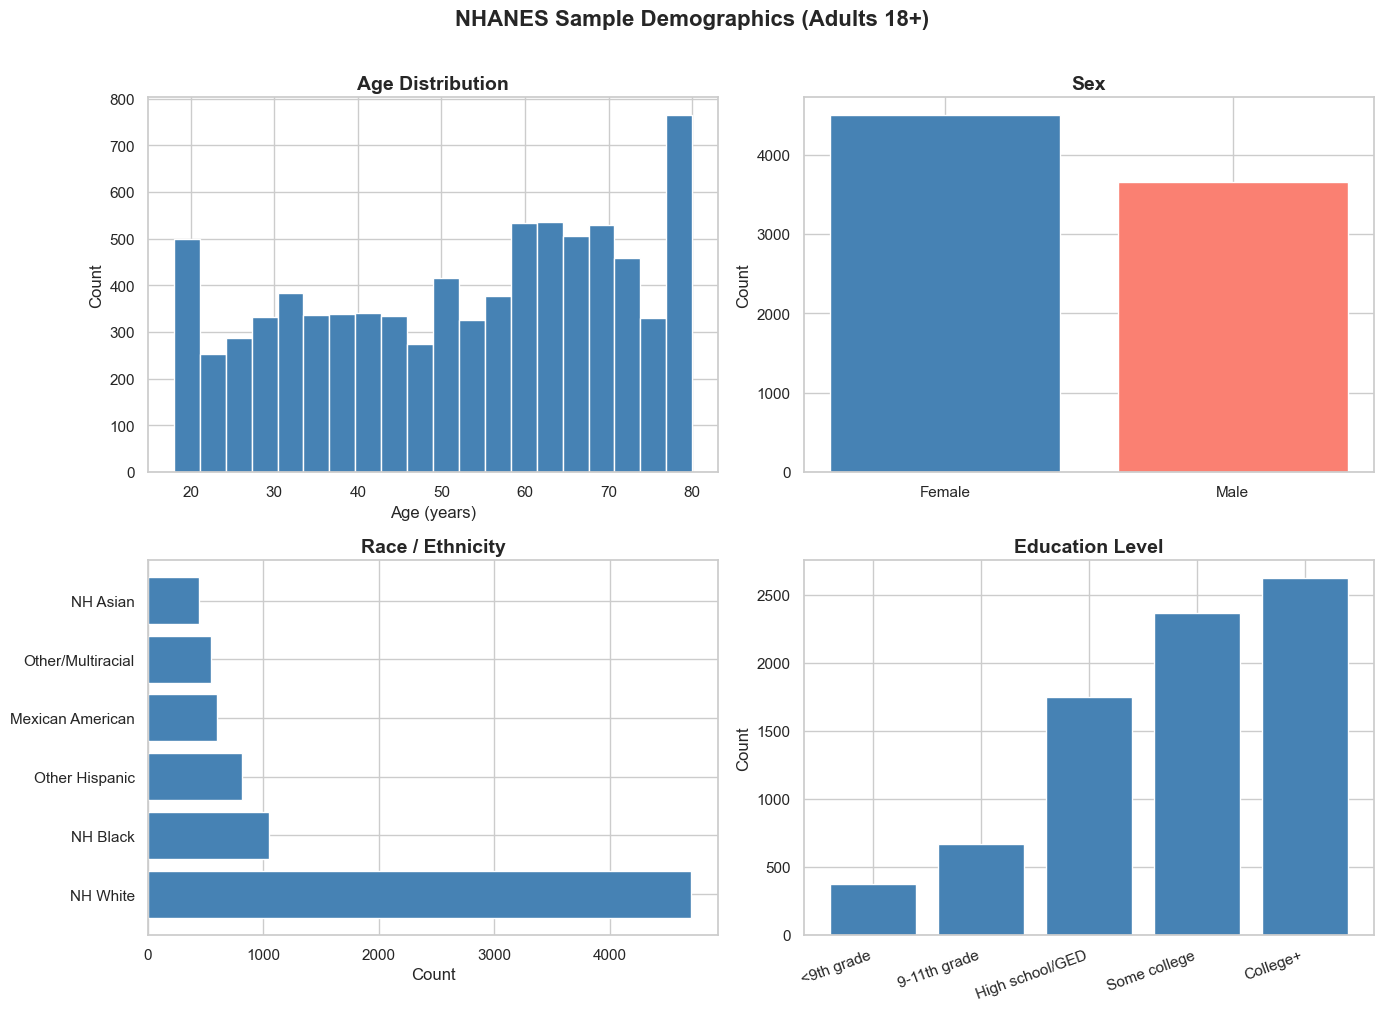

Mean age: 52.1 years
% Female: 55.1%
% with college degree: 32.2%


In [59]:
# ============================================================
# SECTION 1: Who is in this dataset?
# ============================================================
# Before any modeling, we need to understand who we're looking at.
# NHANES is designed to be representative of the U.S. civilian 
# non-institutionalized population. Let's see what that looks like.

race_labels = {1: 'Mexican American', 2: 'Other Hispanic', 
               3: 'NH White', 4: 'NH Black', 
               6: 'NH Asian', 7: 'Other/Multiracial'}

edu_labels = {1: '<9th grade', 2: '9-11th grade', 
              3: 'High school/GED', 4: 'Some college', 5: 'College+'}

df['race_label'] = df['race_ethnicity'].map(race_labels)
df['edu_label']  = df['education'].map(edu_labels)
df['gender_label'] = df['gender'].map({0: 'Male', 1: 'Female'})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('NHANES Sample Demographics (Adults 18+)', fontsize=16, fontweight='bold', y=1.01)

# Age distribution
axes[0,0].hist(df['age'], bins=20, color='steelblue', edgecolor='white')
axes[0,0].set_title('Age Distribution')
axes[0,0].set_xlabel('Age (years)')
axes[0,0].set_ylabel('Count')

# Sex
gender_counts = df['gender_label'].value_counts()
axes[0,1].bar(gender_counts.index, gender_counts.values, color=['steelblue','salmon'])
axes[0,1].set_title('Sex')
axes[0,1].set_ylabel('Count')

# Race/ethnicity
race_counts = df['race_label'].value_counts()
axes[1,0].barh(race_counts.index, race_counts.values, color='steelblue')
axes[1,0].set_title('Race / Ethnicity')
axes[1,0].set_xlabel('Count')

# Education
edu_order = ['<9th grade','9-11th grade','High school/GED','Some college','College+']
edu_counts = df['edu_label'].value_counts().reindex(edu_order)
axes[1,1].bar(edu_counts.index, edu_counts.values, color='steelblue')
axes[1,1].set_title('Education Level')
axes[1,1].set_xticklabels(edu_order, rotation=20, ha='right')
axes[1,1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Quick summary stats
print(f"Mean age: {df['age'].mean():.1f} years")
print(f"% Female: {df['gender_label'].eq('Female').mean()*100:.1f}%")
print(f"% with college degree: {df['edu_label'].eq('College+').mean()*100:.1f}%")

In [61]:
# ============================================================
# Preserve education and flag structural missingness
# ============================================================

# Preserve original education values and missing answers
df['education'] = merged['education'].copy()

# Flag participants who were not asked the adult education question
df['education_not_asked'] = (df['age'] < 20).astype(int)

## Outcome Variable: Hypertension

A participant was classified as hypertensive if any of these
criteria were met:

- Average measured systolic blood pressure ≥130 mmHg
- Average measured diastolic blood pressure ≥80 mmHg
- Reported current use of prescribed blood-pressure medication
  (BPQ150)

A negative outcome required both blood-pressure averages below
these thresholds and either an explicit report of no medication
use or an expected medication-question skip after reporting no
previous hypertension diagnosis.

Participants without enough information to determine an outcome
remained unclassified and were excluded from modeling.
Blood-pressure measurements were not imputed to create outcomes.

Among 8,153 adults:
- 3,829 were classified as hypertensive.
- 2,875 were classified as not hypertensive.
- 1,449 (17.8%) had an unknown outcome.

Hypertension prevalence was 57.1% among the 6,704 adults with
known outcomes. This is an unweighted sample percentage,
not a national prevalence estimate.

Self-reported diagnosis alone did not establish a positive outcome;
it was used to interpret medication-question skips.

## Section 2: What does cardiovascular risk look like?

Now that the data is clean we zoom in on the health variables. Hypertension prevalence, cholesterol distributions, BMI, and smoking are explored across demographic groups. This is where the story starts to emerge — risk is not evenly distributed across the population.

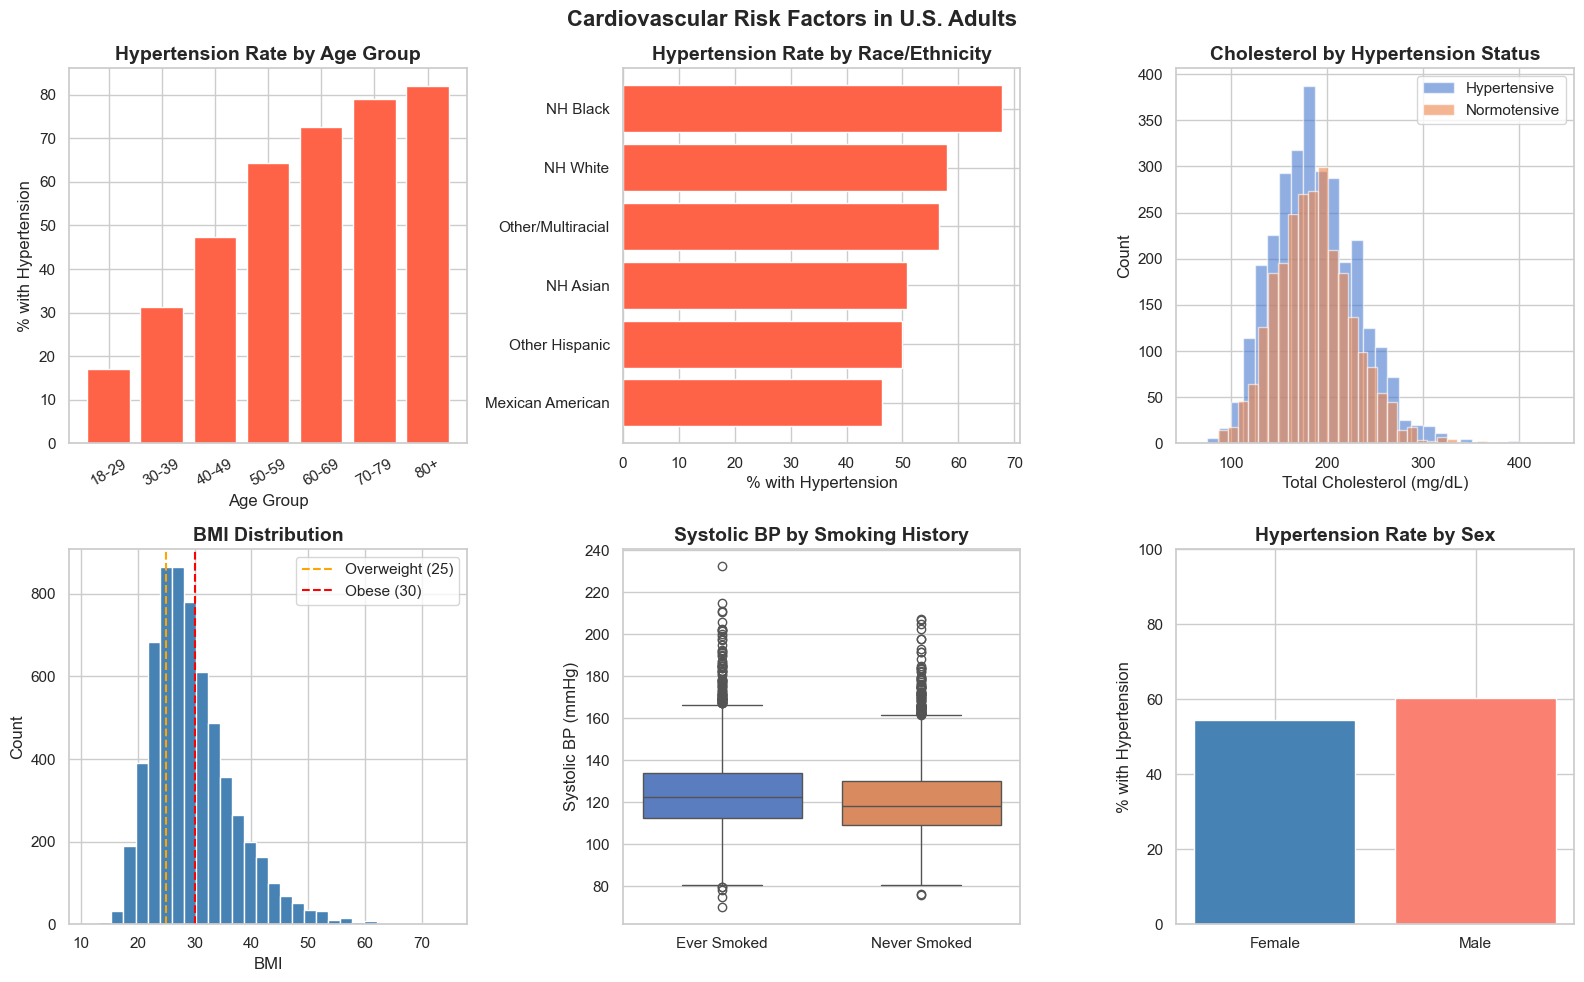

=== Key Findings ===
Overall hypertension prevalence:  57.1%
Hypertension in 18-29 yr olds:    17.0%
Hypertension in 70-79 yr olds:    79.1%
Highest hypertension by race:     NH Black (67.7%)
Lowest hypertension by race:      Mexican American (46.4%)


In [65]:
# ============================================================
# SECTION 2: What does cardiovascular risk look like?
# ============================================================
# Now we zoom in on the health variables. We look at hypertension
# prevalence across demographic groups, cholesterol distributions,
# BMI, and smoking. This is where the story starts to emerge —
# risk is not evenly distributed across the population.

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Cardiovascular Risk Factors in U.S. Adults', fontsize=16, fontweight='bold')

# Hypertension prevalence by age group
df['age_group'] = pd.cut(
    df['age'],
    bins=[18, 30, 40, 50, 60, 70, 80, float('inf')],
    labels=['18-29', '30-39', '40-49', '50-59',
            '60-69', '70-79', '80+'],
    right=False
)
hyp_by_age = df.groupby('age_group', observed=True)['hypertension'].mean() * 100
axes[0,0].bar(hyp_by_age.index, hyp_by_age.values, color='tomato')
axes[0,0].set_title('Hypertension Rate by Age Group')
axes[0,0].set_xlabel('Age Group')
axes[0,0].set_ylabel('% with Hypertension')
axes[0,0].tick_params(axis='x', rotation=30)

# Hypertension by race/ethnicity
hyp_by_race = df.groupby('race_label')['hypertension'].mean().sort_values() * 100
axes[0,1].barh(hyp_by_race.index, hyp_by_race.values, color='tomato')
axes[0,1].set_title('Hypertension Rate by Race/Ethnicity')
axes[0,1].set_xlabel('% with Hypertension')

# Cholesterol distribution by hypertension status
df['htn_label'] = df['hypertension'].map({1.0: 'Hypertensive', 0.0: 'Normotensive'})
for label, grp in df.groupby('htn_label'):
    axes[0,2].hist(grp['total_cholesterol_mgdl'], bins=30, alpha=0.6, label=label)
axes[0,2].set_title('Cholesterol by Hypertension Status')
axes[0,2].set_xlabel('Total Cholesterol (mg/dL)')
axes[0,2].set_ylabel('Count')
axes[0,2].legend()

# BMI distribution
axes[1,0].hist(df['bmi'], bins=30, color='steelblue', edgecolor='white')
axes[1,0].axvline(25, color='orange', linestyle='--', label='Overweight (25)')
axes[1,0].axvline(30, color='red',    linestyle='--', label='Obese (30)')
axes[1,0].set_title('BMI Distribution')
axes[1,0].set_xlabel('BMI')
axes[1,0].set_ylabel('Count')
axes[1,0].legend()

# Systolic BP by smoking status
df['smoke_label'] = df['ever_smoked'].map({1.0: 'Ever Smoked', 0.0: 'Never Smoked'})
sns.boxplot(data=df, x='smoke_label', y='systolic_bp', hue='smoke_label', palette='muted', legend=False, ax=axes[1,1])
axes[1,1].set_title('Systolic BP by Smoking History')
axes[1,1].set_xlabel('')
axes[1,1].set_ylabel('Systolic BP (mmHg)')

# Hypertension rate by sex
hyp_by_sex = df.groupby('gender_label')['hypertension'].mean() * 100
axes[1,2].bar(hyp_by_sex.index, hyp_by_sex.values, color=['steelblue','salmon'])
axes[1,2].set_title('Hypertension Rate by Sex')
axes[1,2].set_ylabel('% with Hypertension')
axes[1,2].set_ylim(0, 100)

plt.tight_layout()
plt.show()

print("=== Key Findings ===")
print(f"Overall hypertension prevalence:  {df['hypertension'].mean()*100:.1f}%")
print(f"Hypertension in 18-29 yr olds:    {hyp_by_age['18-29']:.1f}%")
print(f"Hypertension in 70-79 yr olds:    {hyp_by_age['70-79']:.1f}%")
print(f"Highest hypertension by race:     {hyp_by_race.idxmax()} ({hyp_by_race.max():.1f}%)")
print(f"Lowest hypertension by race:      {hyp_by_race.idxmin()} ({hyp_by_race.min():.1f}%)")

## Section 3: Modeling

With a clean dataset and a clear picture of the risk landscape, we now build a predictive model for hypertension. We start with logistic regression for its interpretability, then compare against a random forest. The goal is not just predictive accuracy — it is a model whose error profile makes sense in a clinical context.

In [71]:
# ============================================================
# SECTION 3: Modeling
# ============================================================
# We have a binary classification problem — predicting whether
# a participant is hypertensive (1) or not (0).
#
# We start with logistic regression because it is interpretable
# and grounded in statistics — coefficients tell us the direction
# and magnitude of each variable's contribution. We then compare
# against a random forest which captures nonlinear relationships
# and gives us feature importance.
#
# Note: systolic_bp, diastolic_bp, told_high_bp, and bp_medication
# are excluded as predictors because they define the outcome
# or directly inform its construction.

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

# Define features and outcome
features = [
    'age', 'gender', 'race_ethnicity', 'education', 
    'education_not_asked',
    'income_poverty_ratio', 'total_cholesterol_mgdl',
    'bmi', 'waist_cm', 'ever_smoked',
    'has_arthritis', 'has_heart_failure', 'has_chd',
    'had_heart_attack', 'had_stroke'
]

# Drop rows where outcome is missing
model_df = df.dropna(subset=['hypertension']).copy()

X = pd.get_dummies(
    model_df[features],
    columns=['race_ethnicity'],
    prefix='race',
    drop_first=True,
    dtype=float
)
features = X.columns.tolist()
y = model_df['hypertension']

print(f"Modeling dataset: {X.shape[0]:,} participants, {X.shape[1]} features")
print(f"Hypertension prevalence in model set: {y.mean()*100:.1f}%")

# Train/test split — 80% train, 20% test
# Random state ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

# Learn replacement values from training data only
for col in continuous_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

for col in categorical_cols:
    mode_val = X_train[col].mode().iloc[0]
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col] = X_test[col].fillna(mode_val)

# Treat refused/don't-know education answers as missing
X_train['education'] = X_train['education'].replace({77: np.nan, 99: np.nan})
X_test['education'] = X_test['education'].replace({77: np.nan, 99: np.nan})

# Learn the most common education category from training adults 20+
edu_mode = X_train.loc[
    X_train['education_not_asked'] == 0, 'education'
].mode().iloc[0]

for data in [X_train, X_test]:
    # Center education around the training mode
    data['education'] = data['education'].fillna(edu_mode) - edu_mode

    # Neutral placeholder for people who weren't asked
    data.loc[data['education_not_asked'] == 1, 'education'] = 0

print(f"\nTraining set: {X_train.shape[0]:,} participants")
print(f"Test set:     {X_test.shape[0]:,} participants")

# Scale features for logistic regression
# Tree-based models don't need scaling but it doesn't hurt
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("\nSetup complete — ready to train models")

Modeling dataset: 6,704 participants, 19 features
Hypertension prevalence in model set: 57.1%

Training set: 5,363 participants
Test set:     1,341 participants

Setup complete — ready to train models


In [73]:
# ============================================================
# Train Logistic Regression and Random Forest
# ============================================================
# We train both models and compare their performance.
# max_iter=1000 gives logistic regression enough iterations
# to converge on this size dataset.
# n_estimators=100 means 100 decision trees in the forest —
# a standard starting point that balances speed and accuracy.

# --- Logistic Regression ---
print("Training Logistic Regression...")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

lr_preds  = lr.predict(X_test_scaled)
lr_probs  = lr.predict_proba(X_test_scaled)[:, 1]
lr_auc    = roc_auc_score(y_test, lr_probs)
print(f"  AUC: {lr_auc:.3f}")

# --- Random Forest ---
print("Training Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_preds  = rf.predict(X_test)
rf_probs  = rf.predict_proba(X_test)[:, 1]
rf_auc    = roc_auc_score(y_test, rf_probs)
print(f"  AUC: {rf_auc:.3f}")

print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test, lr_preds, target_names=['Normotensive','Hypertensive']))

print("--- Random Forest Classification Report ---")
print(classification_report(y_test, rf_preds, target_names=['Normotensive','Hypertensive']))

Training Logistic Regression...
  AUC: 0.802
Training Random Forest...
  AUC: 0.819

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

Normotensive       0.74      0.62      0.68       575
Hypertensive       0.75      0.84      0.79       766

    accuracy                           0.74      1341
   macro avg       0.74      0.73      0.73      1341
weighted avg       0.74      0.74      0.74      1341

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

Normotensive       0.73      0.64      0.68       575
Hypertensive       0.75      0.82      0.78       766

    accuracy                           0.74      1341
   macro avg       0.74      0.73      0.73      1341
weighted avg       0.74      0.74      0.74      1341



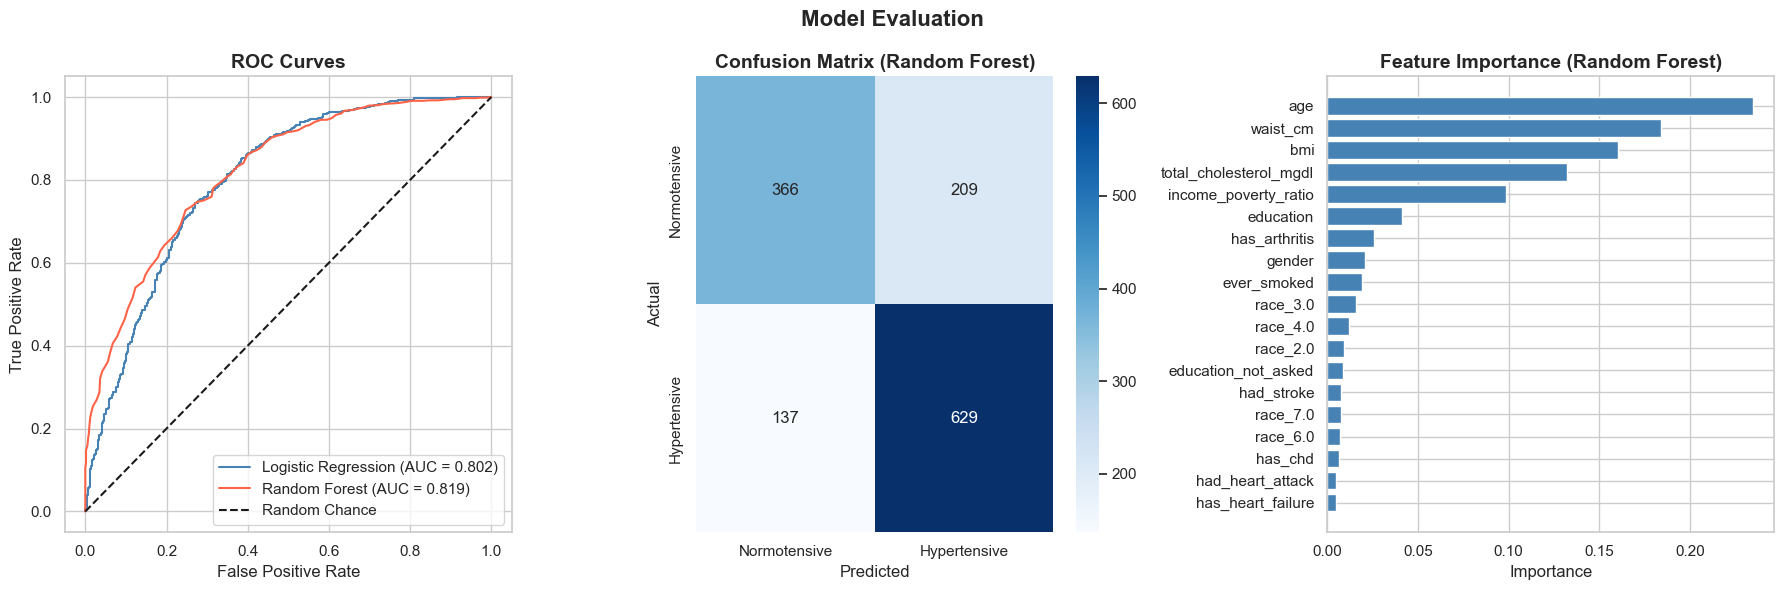

=== Top 5 Most Important Features ===
  age                            0.2348
  waist_cm                       0.1841
  bmi                            0.1602
  total_cholesterol_mgdl         0.1325
  income_poverty_ratio           0.0987


In [77]:
# ============================================================
# Model Evaluation Visualizations
# ============================================================
# Three panels: ROC curves, confusion matrices, feature importance
# ROC curves show the tradeoff between sensitivity and specificity.
# Confusion matrices show exactly where each model goes right/wrong.
# Feature importance reveals which variables are actually driving
# the predictions — this is where the clinical story comes together.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model Evaluation', fontsize=16, fontweight='bold')

# --- ROC Curves ---
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

axes[0].plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.3f})', color='steelblue')
axes[0].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})', color='tomato')
axes[0].plot([0,1], [0,1], 'k--', label='Random Chance')
axes[0].set_title('ROC Curves')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# --- Confusion Matrices ---
# Showing random forest since it performed slightly better
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Normotensive','Hypertensive'],
            yticklabels=['Normotensive','Hypertensive'])
axes[1].set_title('Confusion Matrix (Random Forest)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# --- Feature Importance (Random Forest) ---
importance_df = pd.DataFrame({
    'feature': features,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

axes[2].barh(importance_df['feature'], importance_df['importance'], color='steelblue')
axes[2].set_title('Feature Importance (Random Forest)')
axes[2].set_xlabel('Importance')

plt.tight_layout()
plt.show()

# Print top 5 features
print("=== Top 5 Most Important Features ===")
top5 = importance_df.sort_values('importance', ascending=False).head()
for _, row in top5.iterrows():
    print(f"  {row['feature']:<30} {row['importance']:.4f}")

## Model Tuning: Reducing False Negatives

Baseline logistic regression achieved an AUC of 0.802 and missed
126 hypertensive test participants. Baseline random forest
achieved an AUC of 0.819 and missed 137.

We compared two adjustments:

**Class balancing:** `class_weight='balanced'` weights each class
inversely to its training frequency. Because hypertension is the
majority class here, this gives greater weight to participants
without hypertension. It does not specifically increase the
penalty for missed hypertensive cases.

**Threshold adjustment:** Lowering the classification threshold
from 0.5 to 0.4 flags more participants as positive, trading
additional false positives for fewer false negatives.

Together, these changes reduced logistic regression's missed
cases from 126 to 107, with 86.0% sensitivity and 60.0% specificity.

The 0.4 threshold is an exploratory project choice. Its suitability
for any practical use would require separate validation and an
assessment of the costs of both types of error.

In [79]:
# ============================================================
# Model Tuning: Class Weights + Threshold Adjustment
# ============================================================
# We retrain both models with class_weight='balanced' and then
# lower the classification threshold from 0.5 to 0.4 to further
# reduce false negatives. We compare all four versions side by side.

# --- Tuned Logistic Regression ---
print("Training tuned Logistic Regression...")
lr_tuned = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_tuned.fit(X_train_scaled, y_train)

lr_tuned_probs = lr_tuned.predict_proba(X_test_scaled)[:, 1]
lr_tuned_preds = (lr_tuned_probs >= 0.4).astype(int)  # lowered threshold
lr_tuned_auc   = roc_auc_score(y_test, lr_tuned_probs)

# --- Tuned Random Forest ---
print("Training tuned Random Forest...")
rf_tuned = RandomForestClassifier(n_estimators=100, random_state=42, 
                                   n_jobs=-1, class_weight='balanced')
rf_tuned.fit(X_train, y_train)

rf_tuned_probs = rf_tuned.predict_proba(X_test)[:, 1]
rf_tuned_preds = (rf_tuned_probs >= 0.4).astype(int)  # lowered threshold
rf_tuned_auc   = roc_auc_score(y_test, rf_tuned_probs)

# --- Compare all four models ---
print("\n========== MODEL COMPARISON ==========")
print(f"\n{'Model':<35} {'AUC':>6}")
print("-" * 42)
print(f"{'Logistic Regression (baseline)':<35} {lr_auc:>6.3f}")
print(f"{'Logistic Regression (tuned)':<35} {lr_tuned_auc:>6.3f}")
print(f"{'Random Forest (baseline)':<35} {rf_auc:>6.3f}")
print(f"{'Random Forest (tuned)':<35} {rf_tuned_auc:>6.3f}")

print("\n--- Tuned Logistic Regression ---")
print(classification_report(y_test, lr_tuned_preds, 
                             target_names=['Normotensive','Hypertensive']))

print("--- Tuned Random Forest ---")
print(classification_report(y_test, rf_tuned_preds, 
                             target_names=['Normotensive','Hypertensive']))

Training tuned Logistic Regression...
Training tuned Random Forest...

========== MODEL COMPARISON ==========

Model                                  AUC
------------------------------------------
Logistic Regression (baseline)       0.802
Logistic Regression (tuned)          0.802
Random Forest (baseline)             0.819
Random Forest (tuned)                0.819

--- Tuned Logistic Regression ---
              precision    recall  f1-score   support

Normotensive       0.76      0.60      0.67       575
Hypertensive       0.74      0.86      0.80       766

    accuracy                           0.75      1341
   macro avg       0.75      0.73      0.73      1341
weighted avg       0.75      0.75      0.74      1341

--- Tuned Random Forest ---
              precision    recall  f1-score   support

Normotensive       0.80      0.50      0.62       575
Hypertensive       0.71      0.90      0.79       766

    accuracy                           0.73      1341
   macro avg       0.75

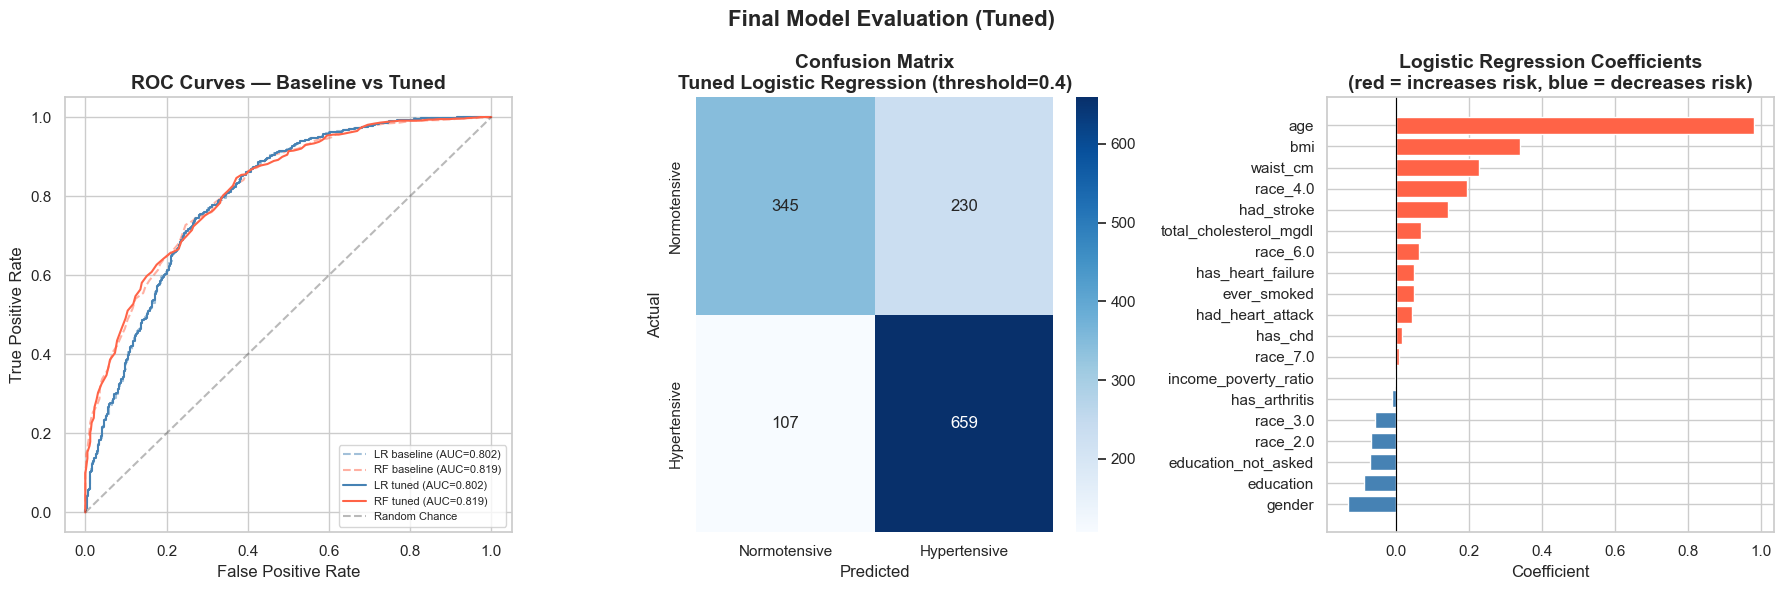

=== Impact of Tuning ===
False negatives (baseline): 126
False negatives (tuned):    107
Reduction:                  19 fewer missed cases

Final model — Tuned Logistic Regression
AUC:                   0.802
Recall (hypertensive): 86.0%

=== Top Risk-Increasing Features ===
       feature  coefficient
0          age     0.981065
6          bmi     0.339772
7     waist_cm     0.228850
16    race_4.0     0.195306
13  had_stroke     0.143044

=== Top Risk-Decreasing Features ===
                feature  coefficient
1                gender    -0.131925
2             education    -0.087895
3   education_not_asked    -0.069381
14             race_2.0    -0.067790
15             race_3.0    -0.056886


In [98]:
# ============================================================
# Final Model Evaluation Visualizations (Tuned Models)
# ============================================================
# Random forest achieved a higher test AUC (0.819) than
# logistic regression (0.802). Logistic regression is retained
# as the primary model for interpretability, with random forest
# as a comparison. Similar AUCs would not establish linearity.
# This cell evaluates the tuned models before calibration.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Final Model Evaluation (Tuned)', fontsize=16, fontweight='bold')

# --- ROC Curves — all four models for transparency ---
lr_fpr, lr_tpr, _             = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _             = roc_curve(y_test, rf_probs)
lr_tuned_fpr, lr_tuned_tpr, _ = roc_curve(y_test, lr_tuned_probs)
rf_tuned_fpr, rf_tuned_tpr, _ = roc_curve(y_test, rf_tuned_probs)

axes[0].plot(lr_fpr, lr_tpr,             linestyle='--', color='steelblue', alpha=0.5, label=f'LR baseline (AUC={lr_auc:.3f})')
axes[0].plot(rf_fpr, rf_tpr,             linestyle='--', color='tomato',    alpha=0.5, label=f'RF baseline (AUC={rf_auc:.3f})')
axes[0].plot(lr_tuned_fpr, lr_tuned_tpr, linestyle='-',  color='steelblue', label=f'LR tuned (AUC={lr_tuned_auc:.3f})')
axes[0].plot(rf_tuned_fpr, rf_tuned_tpr, linestyle='-',  color='tomato',    label=f'RF tuned (AUC={rf_tuned_auc:.3f})')
axes[0].plot([0,1], [0,1], 'k--', alpha=0.3, label='Random Chance')
axes[0].set_title('ROC Curves — Baseline vs Tuned')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8)

# --- Confusion Matrix — tuned logistic regression (final model) ---
cm_tuned = confusion_matrix(y_test, lr_tuned_preds)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Normotensive','Hypertensive'],
            yticklabels=['Normotensive','Hypertensive'])
axes[1].set_title('Confusion Matrix\nTuned Logistic Regression (threshold=0.4)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# --- Logistic Regression Coefficients ---
# Unlike random forest feature importance, coefficients tell us
# both direction and magnitude — a positive coefficient means
# the variable increases hypertension risk, negative means it
# decreases it. This is the key advantage of logistic regression.
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': lr_tuned.coef_[0]
}).sort_values('coefficient', ascending=True)

colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['coefficient']]
axes[2].barh(coef_df['feature'], coef_df['coefficient'], color=colors)
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].set_title('Logistic Regression Coefficients\n(red = increases risk, blue = decreases risk)')
axes[2].set_xlabel('Coefficient')

plt.tight_layout()
plt.show()

# False negative comparison
baseline_fn = confusion_matrix(y_test, lr_preds)[1][0]
tuned_fn    = cm_tuned[1][0]

print("=== Impact of Tuning ===")
print(f"False negatives (baseline): {baseline_fn}")
print(f"False negatives (tuned):    {tuned_fn}")
print(f"Reduction:                  {baseline_fn - tuned_fn} fewer missed cases")
print(f"\nFinal model — Tuned Logistic Regression")
print(f"AUC:                   {lr_tuned_auc:.3f}")
print(f"Recall (hypertensive): {(cm_tuned[1][1] / (cm_tuned[1][0] + cm_tuned[1][1]))*100:.1f}%")

print("\n=== Top Risk-Increasing Features ===")
print(coef_df.sort_values('coefficient', ascending=False).head())
print("\n=== Top Risk-Decreasing Features ===")
print(coef_df.sort_values('coefficient').head())

## Fairness Analysis

A model that performs well overall but poorly for specific demographic groups can cause real harm if deployed. Before drawing any conclusions we check whether the model's recall — our priority metric — is consistent across race/ethnicity, age group, and sex.

=== Model Performance by Race/Ethnicity ===
Group                      N   Recall  Precision     F1
-------------------------------------------------------
Mexican American         117    0.864      0.633  0.731
Other Hispanic           133    0.733      0.821  0.775
NH White                 769    0.869      0.723  0.789
NH Black                 176    0.934      0.807  0.866
NH Asian                  72    0.897      0.778  0.833
Other/Multiracial         74    0.756      0.739  0.747

=== Model Performance by Age Group ===
Group          N   Recall  Precision     F1
-------------------------------------------
18-29        176    0.250      0.545  0.343
30-39        196    0.381      0.585  0.462
40-49        153    0.493      0.565  0.526
50-59        210    0.925      0.771  0.841
60-69        305    0.987      0.753  0.854
70-79        214    1.000      0.762  0.865
80+           87    1.000      0.816  0.899

=== Model Performance by Sex ===
Group          N   Recall  Precision  

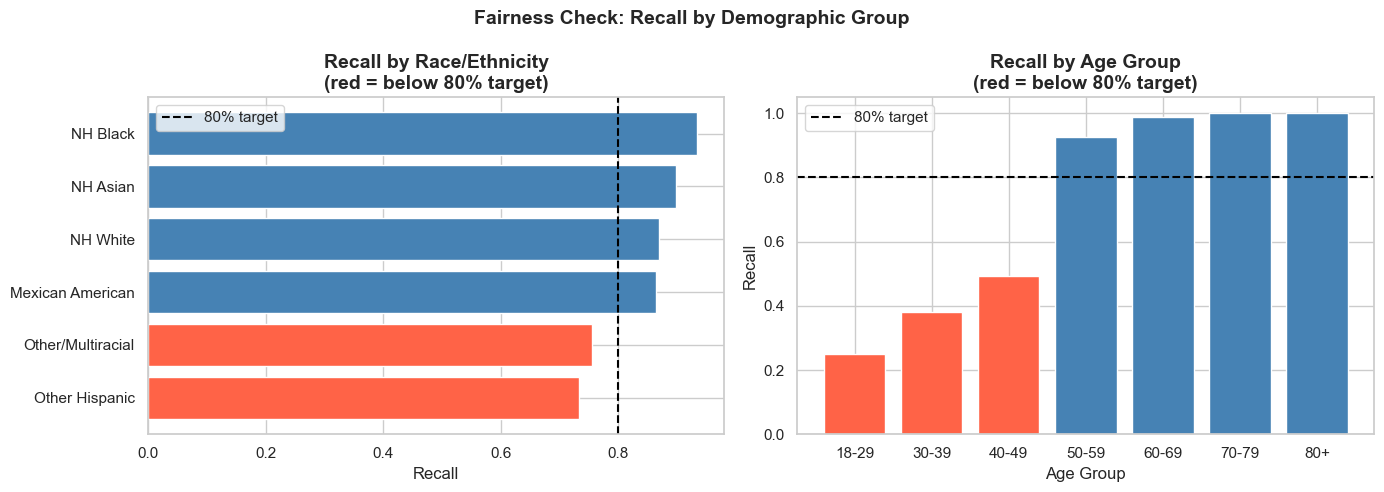

In [83]:
# ============================================================
# Fairness Check: Model Performance by Demographic Subgroup
# ============================================================
# A model that performs well overall but poorly for specific
# demographic groups can cause real harm if deployed. This is
# a subgroup performance gap. We evaluate recall specifically —
# since our priority is minimizing missed hypertensive cases,
# we want to ensure no group is systematically underserved.

from sklearn.metrics import recall_score, precision_score, f1_score

# Add predictions to test set for subgroup analysis
test_df = X_test.copy()
test_df['race_ethnicity'] = model_df.loc[X_test.index, 'race_ethnicity']
test_df['y_true'] = y_test.values
test_df['y_pred'] = lr_tuned_preds
test_df['y_prob'] = lr_tuned_probs

# --- Performance by Race/Ethnicity ---
race_map = {1: 'Mexican American', 2: 'Other Hispanic',
            3: 'NH White', 4: 'NH Black',
            6: 'NH Asian', 7: 'Other/Multiracial'}

print("=== Model Performance by Race/Ethnicity ===")
print(f"{'Group':<22} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 55)

race_results = []
for code, label in race_map.items():
    group = test_df[test_df['race_ethnicity'] == code]
    if len(group) < 20:
        continue
    hyp_group = group[group['y_true'] == 1]
    if len(hyp_group) == 0:
        continue
    recall    = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred'], zero_division=0)
    race_results.append({'group': label, 'n': len(group), 
                         'recall': recall, 'precision': precision, 'f1': f1})
    print(f"{label:<22} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# --- Performance by Age Group ---
test_df['age_group'] = pd.cut(
    test_df['age'],
    bins=[18, 30, 40, 50, 60, 70, 80, float('inf')],
    labels=['18-29', '30-39', '40-49', '50-59',
            '60-69', '70-79', '80+'],
    right=False
)

print("\n=== Model Performance by Age Group ===")
print(f"{'Group':<10} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 43)

for group_name, group in test_df.groupby('age_group', observed=True):
    if len(group) < 20:
        continue
    recall    = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred'], zero_division=0)
    print(f"{str(group_name):<10} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# --- Performance by Sex ---
print("\n=== Model Performance by Sex ===")
print(f"{'Group':<10} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 43)

for code, label in {0: 'Male', 1: 'Female'}.items():
    group     = test_df[test_df['gender'] == code]
    recall    = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred'], zero_division=0)
    print(f"{label:<10} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# --- Visualize recall gaps ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Fairness Check: Recall by Demographic Group', 
             fontsize=14, fontweight='bold')

# Race recall
race_df = pd.DataFrame(race_results).sort_values('recall')
colors  = ['tomato' if r < 0.80 else 'steelblue' for r in race_df['recall']]
axes[0].barh(race_df['group'], race_df['recall'], color=colors)
axes[0].axvline(0.80, color='black', linestyle='--', label='80% target')
axes[0].set_title('Recall by Race/Ethnicity\n(red = below 80% target)')
axes[0].set_xlabel('Recall')
axes[0].legend()

# Age recall
age_recalls, age_labels = [], []
for group_name, group in test_df.groupby('age_group', observed=True):
    if len(group) < 20:
        continue
    age_recalls.append(recall_score(group['y_true'], group['y_pred'], zero_division=0))
    age_labels.append(str(group_name))

colors = ['tomato' if r < 0.80 else 'steelblue' for r in age_recalls]
axes[1].bar(age_labels, age_recalls, color=colors)
axes[1].axhline(0.80, color='black', linestyle='--', label='80% target')
axes[1].set_title('Recall by Age Group\n(red = below 80% target)')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Recall')
axes[1].legend()

plt.tight_layout()
plt.show()

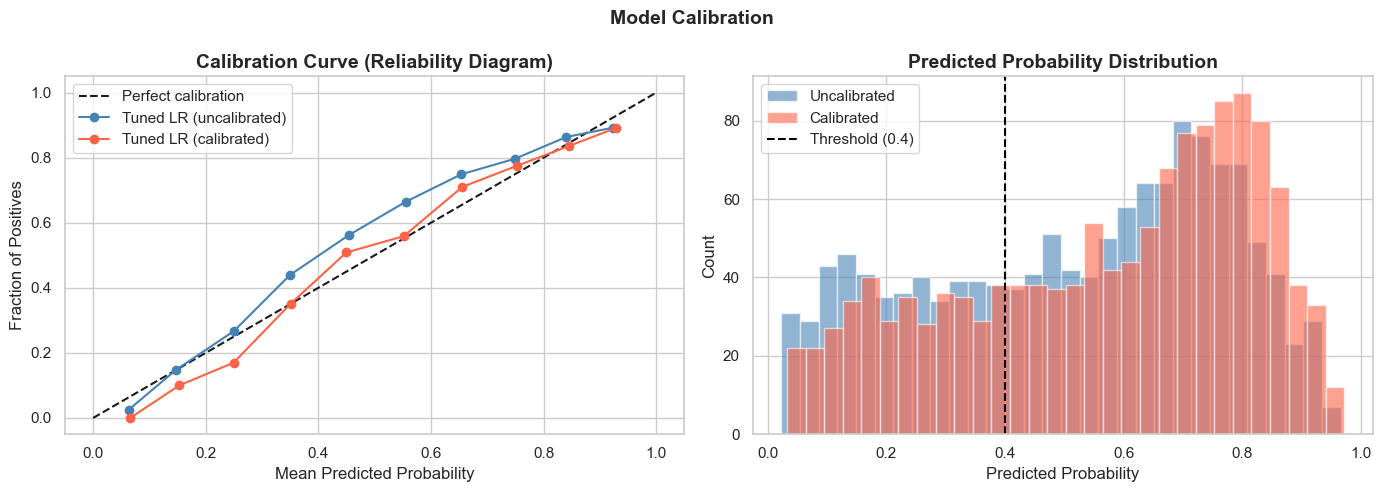

=== Calibration Impact ===
Model                                  AUC   Recall
----------------------------------------------------
Tuned LR (uncalibrated)              0.802    0.860
Tuned LR (calibrated)                0.802    0.913


In [85]:
# ============================================================
# Calibration Check
# ============================================================
# A well-calibrated model means that when it predicts a 70% 
# probability of hypertension, roughly 70% of those patients 
# are actually hypertensive. Poor calibration means the 
# probability scores are misleading even if AUC looks good.
#
# We use a calibration curve (reliability diagram) to visualize
# this. A perfectly calibrated model follows the diagonal line.
# Points above the diagonal = model is underconfident
# Points below the diagonal = model is overconfident

from sklearn.calibration import calibration_curve, CalibratedClassifierCV

# Check calibration of tuned logistic regression
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, lr_tuned_probs, n_bins=10
)

# Also train a calibrated version using Platt scaling
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Use predictors before imputation so each calibration fold
# learns its own replacement values and scaling.
X_cal = X.copy()
X_cal['education'] = X_cal['education'].replace(
    {77: np.nan, 99: np.nan}
)
X_cal.loc[X_cal['education_not_asked'] == 1, 'education'] = 0

other_cols = [c for c in features if c not in continuous_cols]

preprocessor = ColumnTransformer([
    ('continuous', SimpleImputer(strategy='median'), continuous_cols),
    ('other', SimpleImputer(strategy='most_frequent'), other_cols)
])

calibration_pipeline = make_pipeline(
    preprocessor,
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    )
)

lr_calibrated = CalibratedClassifierCV(
    calibration_pipeline,
    method='sigmoid',
    cv=5
)
lr_calibrated.fit(X_cal.loc[X_train.index], y_train)

lr_calibrated_probs = lr_calibrated.predict_proba(
    X_cal.loc[X_test.index]
)[:, 1]
lr_calibrated_preds = (lr_calibrated_probs >= 0.4).astype(int)

frac_pos_cal, mean_pred_cal = calibration_curve(
    y_test, lr_calibrated_probs, n_bins=10
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Calibration', fontsize=14, fontweight='bold')

# Calibration curves
axes[0].plot([0,1], [0,1], 'k--', label='Perfect calibration')
axes[0].plot(mean_predicted_value, fraction_of_positives, 
             'o-', color='steelblue', label='Tuned LR (uncalibrated)')
axes[0].plot(mean_pred_cal, frac_pos_cal,
             'o-', color='tomato', label='Tuned LR (calibrated)')
axes[0].set_title('Calibration Curve (Reliability Diagram)')
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Fraction of Positives')
axes[0].legend()

# Probability distribution
axes[1].hist(lr_tuned_probs, bins=30, alpha=0.6, 
             color='steelblue', label='Uncalibrated')
axes[1].hist(lr_calibrated_probs, bins=30, alpha=0.6, 
             color='tomato', label='Calibrated')
axes[1].axvline(0.4, color='black', linestyle='--', label='Threshold (0.4)')
axes[1].set_title('Predicted Probability Distribution')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

# Compare performance
cal_auc    = roc_auc_score(y_test, lr_calibrated_probs)
cal_recall = recall_score(y_test, lr_calibrated_preds)

print("=== Calibration Impact ===")
print(f"{'Model':<35} {'AUC':>6} {'Recall':>8}")
print("-" * 52)
print(f"{'Tuned LR (uncalibrated)':<35} {lr_tuned_auc:>6.3f} {recall_score(y_test, lr_tuned_preds):>8.3f}")
print(f"{'Tuned LR (calibrated)':<35} {cal_auc:>6.3f} {cal_recall:>8.3f}")


=== Final Model: Calibrated Logistic Regression ===
AUC:                   0.802
Recall (hypertensive): 91.3%
F1 (hypertensive):     0.804

              precision    recall  f1-score   support

Normotensive       0.82      0.52      0.64       575
Hypertensive       0.72      0.91      0.80       766

    accuracy                           0.75      1341
   macro avg       0.77      0.72      0.72      1341
weighted avg       0.76      0.75      0.73      1341


=== Updated Fairness Check (Calibrated Model) ===
Group                      N   Recall  Precision     F1
-------------------------------------------------------
Mexican American         117    0.909      0.571  0.702
Other Hispanic           133    0.840      0.797  0.818
NH White                 769    0.912      0.708  0.797
NH Black                 176    0.975      0.787  0.871
NH Asian                  72    0.949      0.725  0.822
Other/Multiracial         74    0.844      0.704  0.768

=== False Negative Progression ==

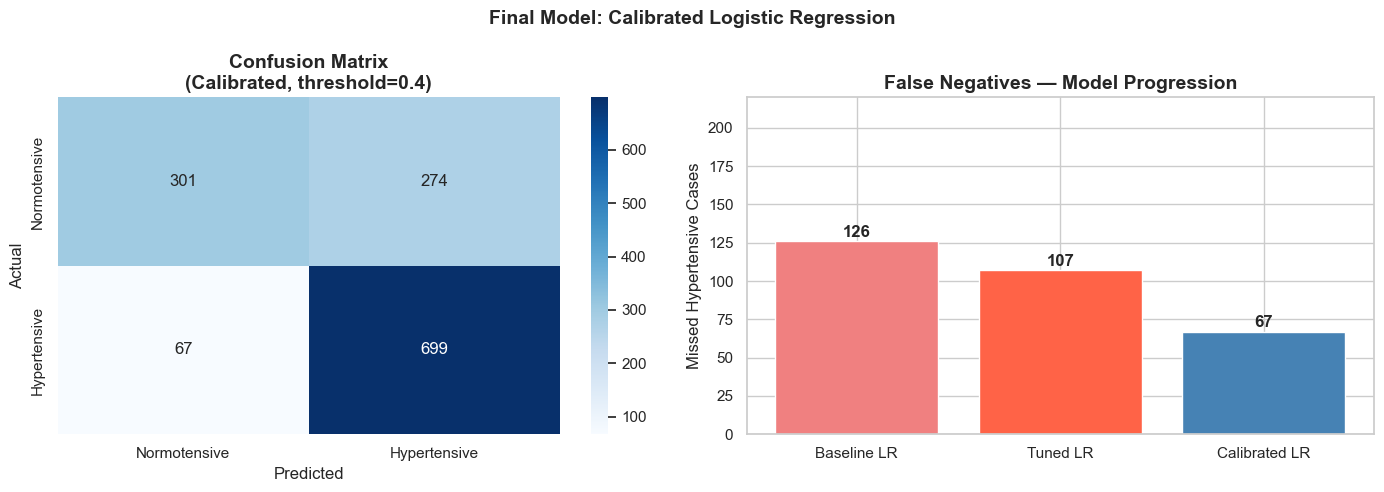

In [87]:
# ============================================================
# Final Model: Calibrated Logistic Regression
# ============================================================
# Five-fold sigmoid calibration is evaluated at threshold 0.4.
# Recall is 91.3%, versus 86.0% for the earlier tuned model.
# Both AUCs round to 0.802. Higher recall alone does not prove
# improved calibration or clinically reliable probabilities.
# Education preprocessing also differs; this is not a controlled
# calibration-only comparison.

# Final predictions using calibrated model
final_probs = lr_calibrated_probs
final_preds = lr_calibrated_preds

print("=== Final Model: Calibrated Logistic Regression ===")
print(f"AUC:                   {roc_auc_score(y_test, final_probs):.3f}")
print(f"Recall (hypertensive): {recall_score(y_test, final_preds)*100:.1f}%")
print(f"F1 (hypertensive):     {f1_score(y_test, final_preds):.3f}")
print()
print(classification_report(y_test, final_preds,
                             target_names=['Normotensive','Hypertensive']))

# Updated confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Final Model: Calibrated Logistic Regression', 
             fontsize=14, fontweight='bold')

# Confusion matrix
cm_final = confusion_matrix(y_test, final_preds)
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normotensive','Hypertensive'],
            yticklabels=['Normotensive','Hypertensive'])
axes[0].set_title('Confusion Matrix\n(Calibrated, threshold=0.4)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Updated fairness check by race
print("\n=== Updated Fairness Check (Calibrated Model) ===")
print(f"{'Group':<22} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 55)

test_df['y_pred_cal'] = final_preds
test_df['y_prob_cal'] = final_probs

race_results_cal = []
for code, label in race_map.items():
    group = test_df[test_df['race_ethnicity'] == code]
    if len(group) < 20:
        continue
    if len(group[group['y_true'] == 1]) == 0:
        continue
    recall    = recall_score(group['y_true'], group['y_pred_cal'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred_cal'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred_cal'], zero_division=0)
    race_results_cal.append({'group': label, 'recall': recall})
    print(f"{label:<22} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# False negative comparison across all versions
fn_baseline  = confusion_matrix(y_test, lr_preds)[1][0]
fn_tuned     = confusion_matrix(y_test, lr_tuned_preds)[1][0]
fn_calibrated = cm_final[1][0]

print("\n=== False Negative Progression ===")
print(f"Baseline logistic regression: {fn_baseline} missed cases")
print(f"Tuned (class weights + 0.4):  {fn_tuned} missed cases")
print(f"Calibrated (final model):     {fn_calibrated} missed cases")
print(f"Total improvement:            {fn_baseline - fn_calibrated} fewer missed cases")

axes[1].bar(['Baseline LR', 'Tuned LR', 'Calibrated LR'],
            [fn_baseline, fn_tuned, fn_calibrated],
            color=['lightcoral', 'tomato', 'steelblue'])
axes[1].set_title('False Negatives — Model Progression')
axes[1].set_ylabel('Missed Hypertensive Cases')
axes[1].set_ylim(0, 220)
for i, v in enumerate([fn_baseline, fn_tuned, fn_calibrated]):
    axes[1].text(i, v + 3, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [89]:
# ============================================================
# Extended Fairness Audit
# ============================================================
# Our initial fairness check measured recall by subgroup.
# Here we go further with two additional metrics:
#
# 1. AUC by subgroup — overall AUC can look fine while being
#    much worse for a specific group. This catches that.
#
# 2. False Negative Rate (FNR) by subgroup — explicitly frames
#    missed cases as a rate of harm rather than just a performance
#    metric. More clinically meaningful than recall alone.

from sklearn.metrics import roc_auc_score, confusion_matrix

def false_negative_rate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn / (fn + tp)

# Build audit dataframe
test_audit = X_test.copy()
test_audit['race_ethnicity'] = model_df.loc[X_test.index, 'race_ethnicity']
test_audit['true'] = y_test.values
test_audit['pred'] = final_preds
test_audit['prob'] = final_probs

# --- AUC by Race/Ethnicity ---
print("=== AUC by Race/Ethnicity ===")
print(f"{'Group':<22} {'N':>5} {'AUC':>8} {'FNR':>8}")
print("-" * 47)

for code, label in race_map.items():
    group = test_audit[test_audit['race_ethnicity'] == code]
    if len(group) < 20 or group['true'].nunique() < 2:
        continue
    auc = roc_auc_score(group['true'], group['prob'])
    fnr = false_negative_rate(group['true'], group['pred'])
    print(f"{label:<22} {len(group):>5} {auc:>8.3f} {fnr:>8.3f}")

# --- AUC and FNR by Age Group ---
test_audit['age_group'] = pd.cut(
    test_audit['age'],
    bins=[18, 30, 40, 50, 60, 70, 80, float('inf')],
    labels=['18-29', '30-39', '40-49', '50-59',
            '60-69', '70-79', '80+'],
    right=False
)

print("\n=== AUC by Age Group ===")
print(f"{'Group':<10} {'N':>5} {'AUC':>8} {'FNR':>8}")
print("-" * 35)

for group_name, group in test_audit.groupby('age_group', observed=True):
    if len(group) < 20 or group['true'].nunique() < 2:
        continue
    auc = roc_auc_score(group['true'], group['prob'])
    fnr = false_negative_rate(group['true'], group['pred'])
    print(f"{str(group_name):<10} {len(group):>5} {auc:>8.3f} {fnr:>8.3f}")

# --- AUC and FNR by Sex ---
print("\n=== AUC by Sex ===")
print(f"{'Group':<10} {'N':>5} {'AUC':>8} {'FNR':>8}")
print("-" * 35)

for code, label in {0: 'Male', 1: 'Female'}.items():
    group = test_audit[test_audit['gender'] == code]
    auc   = roc_auc_score(group['true'], group['prob'])
    fnr   = false_negative_rate(group['true'], group['pred'])
    print(f"{label:<10} {len(group):>5} {auc:>8.3f} {fnr:>8.3f}")

# --- Positive prediction rate by group (demographic parity check) ---
print("\n=== Positive Prediction Rate by Race/Ethnicity ===")
print("(What % of each group does the model flag as hypertensive)")
print(f"{'Group':<22} {'Predicted Positive Rate':>25}")
print("-" * 50)

for code, label in race_map.items():
    group = test_audit[test_audit['race_ethnicity'] == code]
    if len(group) < 20:
        continue
    rate = group['pred'].mean() * 100
    print(f"{label:<22} {rate:>24.1f}%")

=== AUC by Race/Ethnicity ===
Group                      N      AUC      FNR
-----------------------------------------------
Mexican American         117    0.811    0.091
Other Hispanic           133    0.853    0.160
NH White                 769    0.781    0.088
NH Black                 176    0.865    0.025
NH Asian                  72    0.838    0.051
Other/Multiracial         74    0.694    0.156

=== AUC by Age Group ===
Group          N      AUC      FNR
-----------------------------------
18-29        176    0.812    0.708
30-39        196    0.740    0.349
40-49        153    0.629    0.310
50-59        210    0.711    0.034
60-69        305    0.679    0.004
70-79        214    0.719    0.000
80+           87    0.460    0.000

=== AUC by Sex ===
Group          N      AUC      FNR
-----------------------------------
Male         594    0.778    0.069
Female       747    0.815    0.104

=== Positive Prediction Rate by Race/Ethnicity ===
(What % of each group does the model f

In [91]:
# ============================================================
# Statsmodels Logistic Regression
# ============================================================
# Separate exploratory unweighted, unpenalized regression.
# P-values are not p-values for the calibrated prediction ensemble.
# Standard errors ignore survey design and imputation uncertainty.
# Inputs, including dummy indicators, are standardized: coefficients
# are per training SD, not raw binary category contrasts.

import statsmodels.api as sm

# Race categories are already encoded in the model inputs.
X_train_sm = pd.DataFrame(
    X_train_scaled,
    columns=features,
    index=X_train.index
)

X_train_sm = sm.add_constant(
    X_train_sm,
    has_constant='add'
)

# Same training participants; preprocessing follows the earlier LR
y_sm = y_train

logit_model = sm.Logit(y_sm, X_train_sm)
result      = logit_model.fit(disp=0)  # disp=0 suppresses iteration output

print(result.summary2(alpha=0.05))

# Pull out significant predictors only
print("\n=== Statistically Significant Predictors (p < 0.05) ===")
summary_df = pd.DataFrame({
    'feature': X_train_sm.columns,
    'coef':       result.params,
    'pvalue':     result.pvalues,
    'ci_lower':   result.conf_int()[0],
    'ci_upper':   result.conf_int()[1]
})
sig = summary_df[summary_df['pvalue'] < 0.05].sort_values('coef', ascending=False)
print(sig.to_string(index=False))

                            Results: Logit
Model:                Logit              Method:             MLE      
Dependent Variable:   hypertension       Pseudo R-squared:   0.213    
Date:                 2026-10-16 13:01   AIC:                5807.1701
No. Observations:     5363               BIC:                5938.9157
Df Model:             19                 Log-Likelihood:     -2883.6  
Df Residuals:         5343               LL-Null:            -3662.9  
Converged:            1.0000             LLR p-value:        0.0000   
No. Iterations:       6.0000             Scale:              1.0000   
----------------------------------------------------------------------
                        Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
----------------------------------------------------------------------
const                   0.3330   0.0331 10.0682 0.0000  0.2682  0.3979
age                     0.9861   0.0436 22.6154 0.0000  0.9007  1.0716
gender                 -0.1372   0

## Key Findings & Conclusions

This project used NHANES August 2021–August 2023 data to
explore factors associated with current hypertension status.

Of 8,153 adults, 6,704 had a known hypertension outcome and
were included in modeling. The stratified split contained
5,363 training participants and 1,341 test participants.

### Model Performance

Random forest achieved a higher test AUC (0.819) than logistic
regression (0.802). Logistic regression was retained as the
primary model for interpretability, with random forest as
a comparison.

At a classification threshold of 0.4, calibrated logistic
regression achieved:
- AUC: 0.802
- Sensitivity (recall): 91.3%
- Specificity: 52.3%
- Accuracy: 74.6%
- Hypertensive-class F1: 0.804

Missed hypertensive cases decreased from 126 at baseline
to 107 after class balancing and threshold adjustment,
and to 67 after calibration. The final model also produced
274 false positives, illustrating the sensitivity–specificity
tradeoff.

### Associated Factors

In a separate, exploratory unweighted Statsmodels regression,
age, BMI, waist circumference, prior stroke, total cholesterol,
sex, education, and the Non-Hispanic Black category relative
to Mexican American participants had p-values below 0.05.

These are adjusted associations, not causal effects.
The Statsmodels regression is separate from the calibrated
prediction model.

### Subgroup Performance

All evaluated race/ethnicity groups exceeded the project's
80% recall target, although estimates are uncertain for
smaller groups.

Age differences remained substantial. The final model missed
70.8% of hypertensive participants aged 18–29, 34.9% aged
30–39, and 31.0% aged 40–49. Strong overall recall therefore
does not imply reliable screening across age groups.

### Limitations

- Survey weights and complex survey design were not incorporated;
  results describe this sample rather than the U.S. population.
- Adults with unknown outcomes were excluded, which may introduce
  selection bias.
- Missing predictors were imputed; imputation does not recover
  the information that was not observed.
- Data are cross-sectional: the model classifies current status,
  rather than predicting future hypertension.
- Findings come from one exploratory train/test split, with no
  external validation or subgroup confidence intervals.
- Calibration does not guarantee accurate individual probabilities.

This is a portfolio and research demonstration, not a validated
clinical screening or diagnostic tool.

**Comparison detail:** The calibrated pipeline uses uncentered education
categories and a zero placeholder for participants under 20. Earlier
models use centered education and a neutral placeholder. The comparison
includes preprocessing and cross-validation differences as well as
sigmoid calibration; recall changes cannot be attributed exclusively
to calibration.


## Model Governance & Ethics

### Intended Use

This project demonstrates hypertension classification, model
evaluation, and subgroup auditing using public NHANES data.

It is intended for academic and portfolio use. It has not been
validated for clinical screening, diagnosis, treatment decisions,
or decisions about insurance, employment, or access to care.

### Error Tradeoffs

At a threshold of 0.4, calibrated logistic regression identified
699 of 766 hypertensive test participants and missed 67.
It also flagged 274 of 575 participants without hypertension.

Sensitivity was 91.3%, while specificity was 52.3%.
Reducing missed cases therefore came with substantial unnecessary
follow-up if these predictions were used in practice.

The 0.4 threshold is an exploratory choice, not an established
clinical cutoff. Any practical application would require
independent validation and assessment of both types of error.

### Performance Across Groups

All evaluated race/ethnicity groups exceeded the project's
80% recall target. This target is a project benchmark, not
a clinical standard or proof of fairness.

| Race/Ethnicity | Test N | AUC | Recall | False Negative Rate |
|---|---:|---:|---:|---:|
| Mexican American | 117 | 0.811 | 90.9% | 9.1% |
| Other Hispanic | 133 | 0.853 | 84.0% | 16.0% |
| Non-Hispanic White | 769 | 0.781 | 91.2% | 8.8% |
| Non-Hispanic Black | 176 | 0.865 | 97.5% | 2.5% |
| Non-Hispanic Asian | 72 | 0.838 | 94.9% | 5.1% |
| Other/Multiracial | 74 | 0.694 | 84.4% | 15.6% |

Test N includes both outcome classes. Recall is calculated
among participants with hypertension, so its denominator
is smaller than the total group size.

Differences remain, and estimates for smaller groups are
uncertain. Confidence intervals and independent validation
would be needed before drawing strong conclusions.

### Age Is the Largest Recall Gap

| Age Group | Test N | AUC | False Negative Rate |
|---|---:|---:|---:|
| 18–29 | 176 | 0.812 | 70.8% |
| 30–39 | 196 | 0.740 | 34.9% |
| 40–49 | 153 | 0.629 | 31.0% |
| 50–59 | 210 | 0.711 | 3.4% |
| 60–69 | 305 | 0.679 | 0.4% |
| 70–79 | 214 | 0.719 | 0.0% |
| 80+ | 87 | 0.460 | 0.0% |

The model missed most hypertensive participants aged 18–29
at the selected threshold, despite an AUC of 0.812 in that
group. Ranking performance and threshold-based recall measure
different aspects of performance.

Conversely, zero missed cases in older groups does not establish
strong discrimination. For participants aged 80+, AUC was 0.460.
Specificity and positive prediction rates are also needed to
understand performance within age groups.

### Performance by Sex

| Sex | Test N | AUC | False Negative Rate |
|---|---:|---:|---:|
| Male | 594 | 0.778 | 6.9% |
| Female | 747 | 0.815 | 10.4% |

These are descriptive differences in this test sample.
They do not establish why the differences occurred.

### Race, Interpretation, and Fairness

Race/ethnicity was included as a categorical predictor.
It should not be interpreted as a biological cause of hypertension.

A separate exploratory Statsmodels regression found an
association for the Non-Hispanic Black category relative to
Mexican American participants after adjustment for the included
variables. Statistical significance does not establish causality,
and nonsignificance would not mean a model ignores a feature.

Differences in positive prediction rates do not, by themselves,
demonstrate discrimination or account for differences in
underlying outcome prevalence.

No group-specific thresholds were implemented.

### Calibration and Transparency

Sigmoid calibration used five-fold cross-validation within the
training set. Imputation and scaling were fitted within each fold.

At the same 0.4 threshold, recall increased from 86.0% to 91.3%,
while AUC remained 0.802 to three decimal places.

Higher recall does not by itself establish better calibration.
Reliability diagrams provide a descriptive check, and calibration
may differ across groups or future datasets. Individual probability
scores should not be presented as clinically validated risks.

### Data and Validation Limits

- Results are unweighted and do not incorporate the NHANES complex
  survey design.
- Of 8,153 adults, 1,449 had unknown outcomes and were excluded
  from modeling. Exclusion may affect representativeness.
- Predictor missingness was handled through imputation.
- Cross-sectional data support current-status classification,
  not causal conclusions or future-risk prediction.
- Model comparisons used one exploratory train/test split.
  The test set was inspected across several model variants,
  so a new independent evaluation is needed before deployment.
- Subgroup confidence intervals and external validation were
  outside this project's scope.

### Requirements Before Any Practical Use

Any practical use would require independent validation,
subgroup uncertainty estimates, assessment of false-positive
burden, and review by appropriate clinical and data-governance
professionals.

A deployment plan would also need an accountable owner,
privacy protections, monitoring of calibration and subgroup
errors, and a process for reviewing model changes.

The present model should remain an educational and research
demonstration.

**Comparison detail:** The calibrated pipeline uses uncentered education
categories and a zero placeholder for participants under 20. Earlier
models use centered education and a neutral placeholder. The comparison
includes preprocessing and cross-validation differences as well as
sigmoid calibration; recall changes cannot be attributed exclusively
to calibration.
